## Get the legs distribution

In [1]:
%matplotlib inline

In [2]:
import sys, os
sys.path.append(os.path.join(os.path.dirname(os.curdir), 'lib'))

In [3]:
import os
import numpy as np
import pandas as pd
import dataset_importers as di

In [4]:
#TODO improve performance (maybe dont use apply)
def assign_tripPurpose(x):
    tpo = x.TripPurpFrom_B01ID
    tpd = x.TripPurpTo_B01ID
    
    if tpd=='Home':
        tpo, tpd = tpd, tpo

    if tpo=='Home':
        purpose = 'HB{}'.format(tpd[0])
    elif tpo==tpd=='Work':
        purpose = 'EB'
    else:
        purpose = 'NHB{}'.format(tpd[0])
    
    return purpose
    

In [5]:
def convert_dtype(v):
    # First try to cast int, then float
    try:
        v = int(v)
        return v
    except:
        pass
    
    try:
        v = float(v)
        return v
    except:
        # Return original value
        return v

In [6]:
def convert_to_interval(x, delim='-', closed='right'):
    left, right = x.split(delim, 1)
    
    left = convert_dtype(left)
    right = convert_dtype(right)
    
    interv = pd.Interval(left, right, closed=closed)
    
    return interv

In [7]:
def prepare_dist_labes_from_bins(bins, concat_char='-'):
    labels = []
    for v, w in zip(bins[:-1], bins[1:]):
        labels.append('{}{}{}'.format(v, concat_char, w))
    labels[-1] = '{}+'.format(bins[-2])
    return labels

In [8]:
def fullTrip_includes_work(x):
    # Check if trip includes a leg to work    
    if 'Work' in x.values:
        return True
    return False

In [9]:
def add_tour_id(df, col_name='TourId'):
    # Every time the cumsum of departures from home equals the cumsum of arrivals to home we have a new tour
    cumsum_departures_home = (df.TripPurpFrom=='Home').cumsum()
    cumsum_arrivals_home = (df.TripPurpTo=='Home').cumsum()
    
    returned_home = (cumsum_departures_home - cumsum_arrivals_home) == 0
    
    # Every time a trip returns home returned_home=0, thus the cumsum can give the id
    tour_id = returned_home.cumsum()
    
    # The cumsum must be shifted up by one
    tour_id = tour_id.shift(1).fillna(method='bfill').astype(int)
    df[col_name] = tour_id
    return df

# Inputs

In [10]:
# Dictionary with the mapping of minutes (lower limit) to timeperiods
keys = [0, 420, 600, 960, 1140, 1440]
vals =['OP1', 'AM', 'IP', 'PM', 'OP2']

d_minutes_to_timeperiods = dict(zip(keys, vals))
d_minutes_to_timeperiods

{0: 'OP1', 420: 'AM', 600: 'IP', 960: 'PM', 1140: 'OP2'}

In [11]:
dist_bins = [0, 10, 25, 50, 100, 9999999]

In [12]:
# Dictionary to replace trip purpose names
keys = ['Home', 'Food shopping', 'Escort education', 'Other escort',
       'Non food shopping', 'Personal business other',
       'Entertain /  public activity', 'Visit friends', 'Day trip / just walk',
       'Eat / drink with friends', 'Escort shopping / personal business',
       'Sport: participate', 'In course of work', 'Work',
       'Escort in course of work', 'Escort home', 'Escort work',
       'Personal business medical', 'Other social', 'Education',
       'Other non-escort', 'Holiday: base', 'Personal business eat / drink']

vals = ['Home', 'Other', 'Other', 'Other',
       'Other', 'Other',
       'Other', 'Other', 'Other',
       'Other', 'Other',
       'Other', 'Other', 'Work',
       'Other', 'Other', 'Other',
       'Other', 'Other', 'Other',
       'Other', 'Other', 'Other']

d_trip_purposes = dict(zip(keys, vals))

# Import files

In [13]:
userhome = os.path.expanduser('~')
userhome = userhome.replace('C:', 'D:')

In [14]:
infolder = os.path.join(userhome, r'OneDrive - Transport Systems Catapult\Modelling\Data\NTS\UKDA-5340-tab')

nts_tables = ['Trip']#, 'Individual']
infile = r'5340_nts_lookup_tables_banded_variables_2015_ukds.xls'
infilepath_metadata = os.path.join(infolder, r'mrdoc\excel', infile)

infolder_ntsdata = infolder

### Import the NTS data

In [15]:
nts = di.get_nts(nts_tables, infolder_ntsdata, infilepath_metadata)

In [17]:
df = nts['Trip'].copy()
df

,SurveyYear,DayID,IndividualID,HouseholdID,PSUID,PersNo,TravDay,JourSeq,HowComp_B01ID,SeriesCall_B01ID,...,TripTotalTime_ImpBin,TripTravTime_ImpBin,TripOrigUA2009_ImpBin,TripOrigUA1998_ImpBin,TripDestUA2009_ImpBin,TripDestUA1998_ImpBin,TripOrigCounty_ImpBin,TripDestCounty_ImpBin,TripOrigGOR_ImpBin,TripDestGOR_ImpBin
TripID,,,,,,,,,,,,,,,,,,,,,
2002000001,2002,2002000002,2002000001,2002000001,2002000001,1,2,1,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002000002,2002,2002000002,2002000001,2002000001,2002000001,1,2,2,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002000003,2002,2002000002,2002000001,2002000001,2002000001,1,2,3,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002000004,2002,2002000002,2002000001,2002000001,2002000001,1,2,4,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002000005,2002,2002000003,2002000001,2002000001,2002000001,1,3,1,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002000006,2002,2002000003,2002000001,2002000001,2002000001,1,3,2,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002000007,2002,2002000003,2002000001,2002000001,2002000001,1,3,3,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002000008,2002,2002000003,2002000001,2002000001,2002000001,1,3,4,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002000009,2002,2002000003,2002000001,2002000001,2002000001,1,3,5,From diary,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Analysis

In [18]:
trips = nts['Trip'].copy()

In [19]:
trips.columns

Index(['SurveyYear', 'DayID', 'IndividualID', 'HouseholdID', 'PSUID', 'PersNo',
       'TravDay', 'JourSeq', 'HowComp_B01ID', 'SeriesCall_B01ID',
       'ShortWalkTrip_B01ID', 'NumStages', 'NumStages_B01ID', 'MainMode_B03ID',
       'MainMode_B04ID', 'MainMode_B11ID', 'TripPurpose_B02ID',
       'TripPurpose_B04ID', 'TripPurpFrom_B01ID', 'TripPurpTo_B01ID',
       'TripPurpose_B01ID', 'TripStartHours', 'TripStartMinutes', 'TripStart',
       'TripStart_B01ID', 'TripStart_B02ID', 'TripEndHours', 'TripEndMinutes',
       'TripEnd', 'TripEnd_B01ID', 'TripEnd_B02ID', 'TripTotalTime',
       'TripTotalTime_B01ID', 'TripTravTime', 'TripTravTime_B01ID',
       'TripOrigGOR_B02ID', 'TripDestGOR_B02ID', 'TripDisIncSW',
       'TripDisIncSW_B01ID', 'TripDisExSW', 'TripDisExSW_B01ID', 'JJXSC',
       'JOTXSC', 'JTTXSC', 'JD', 'W5', 'W5xHH', 'ShortWalkTrip_ImpBin',
       'TripPurpFrom_ImpBin', 'TripPurpTo_ImpBin', 'TripPurpose_ImpBin',
       'TripDis_ImpBin', 'TripTotalTime_ImpBin', 'TripTravTim

In [20]:
trips_cols = ['SurveyYear', 'TravDay', 'IndividualID', 'MainMode_B04ID',
              'TripPurpFrom_B01ID', 'TripPurpTo_B01ID',
              'TripStart', 'TripEnd', 'NumStages', 'TripDisIncSW',
              'TripOrigGOR_B02ID', 'TripDestGOR_B02ID', 'W5', 'JJXSC']
trips = trips[trips_cols]

In [21]:
trips.head(2)

,SurveyYear,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom_B01ID,TripPurpTo_B01ID,TripStart,TripEnd,NumStages,TripDisIncSW,TripOrigGOR_B02ID,TripDestGOR_B02ID,W5,JJXSC
TripID,,,,,,,,,,,,,,
2002000001,2002,2,2002000001,Car / van passenger,Home,Visit friends,675.0,683.0,1,1.0,London,London,0.989618,1
2002000002,2002,2,2002000001,Car / van passenger,Visit friends,Personal business other,720.0,735.0,1,1.0,London,London,1.002945,1


In [22]:
df = trips.copy()
df['WeightTrip'] = df['W5'] * df['JJXSC']
df.drop(['W5', 'JJXSC'], axis=1, inplace=True)
#df.head(2)

### Filter the London trips 

In [23]:
idxslc = pd.IndexSlice

In [24]:
df = df[(df.TripOrigGOR_B02ID == 'London') & (df.TripDestGOR_B02ID == 'London')]
df.drop(['TripOrigGOR_B02ID', 'TripDestGOR_B02ID'], axis=1, inplace=True)
#df.head(2)

In [25]:
trips.columns

Index(['SurveyYear', 'TravDay', 'IndividualID', 'MainMode_B04ID',
       'TripPurpFrom_B01ID', 'TripPurpTo_B01ID', 'TripStart', 'TripEnd',
       'NumStages', 'TripDisIncSW', 'TripOrigGOR_B02ID', 'TripDestGOR_B02ID',
       'W5', 'JJXSC'],
      dtype='object')

In [26]:
# Dictionary to rename modes
grp_mode_keys = list(df.MainMode_B04ID.unique())
grp_mode_vals = ['CarPass', 'CarPass', 'CarDriver', 'Walk', 'Bus', 'Rail', 'Bus', 'Rail', 'Other', 'Other', 'Other', 'Other', 'Other'] 
d_grp_mode = dict(zip(grp_mode_keys, grp_mode_vals))
# Change the name of main mode
df.MainMode_B04ID = df.MainMode_B04ID.map(d_grp_mode)
df.head(2)

,SurveyYear,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom_B01ID,TripPurpTo_B01ID,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
TripID,,,,,,,,,,,
2002000001,2002,2,2002000001,CarPass,Home,Visit friends,675.0,683.0,1,1.0,0.989618
2002000002,2002,2,2002000001,CarPass,Visit friends,Personal business other,720.0,735.0,1,1.0,1.002945


In [27]:
# Rename the trip purposes
df.TripPurpFrom_B01ID = df.TripPurpFrom_B01ID.map(d_trip_purposes)
df.TripPurpTo_B01ID = df.TripPurpTo_B01ID.map(d_trip_purposes)

# Rename the columns
d = {'TripPurpFrom_B01ID': 'TripPurpFrom',
     'TripPurpTo_B01ID': 'TripPurpTo'}

df.rename(columns=d, inplace=True)
df.head(2)

,SurveyYear,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom,TripPurpTo,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
TripID,,,,,,,,,,,
2002000001,2002,2,2002000001,CarPass,Home,Other,675.0,683.0,1,1.0,0.989618
2002000002,2002,2,2002000001,CarPass,Other,Other,720.0,735.0,1,1.0,1.002945


In [28]:
# Filter for 2012 and onwards
df = df[df.SurveyYear >= 2012].copy()
df.drop(['SurveyYear'], axis=1, inplace=True)
df.head()

,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom,TripPurpTo,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
TripID,,,,,,,,,,
2012000007,6,2012000003,CarDriver,Home,Other,600.0,620.0,1,5.0,1.359127
2012000008,6,2012000003,CarDriver,Other,Home,720.0,740.0,1,5.0,1.359127
2012000009,2,2012000004,Rail,Home,Other,810.0,870.0,1,10.0,1.099737
2012000010,2,2012000004,Rail,Other,Home,960.0,1020.0,1,10.0,1.099737
2012000011,3,2012000004,Rail,Home,Other,540.0,600.0,1,10.0,1.099737


In [29]:
df_car = df[df.MainMode_B04ID=='CarDriver'].copy()
df_car.head(2)

,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom,TripPurpTo,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
TripID,,,,,,,,,,
2012000007,6,2012000003,CarDriver,Home,Other,600.0,620.0,1,5.0,1.359127
2012000008,6,2012000003,CarDriver,Other,Home,720.0,740.0,1,5.0,1.359127


In [30]:
df_car.reset_index(inplace=True)

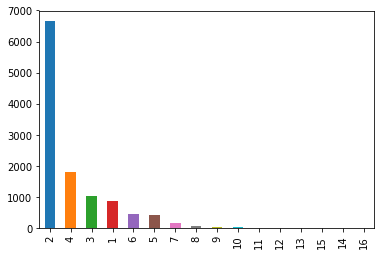

In [31]:
legs_distr = df_car.copy()
legs_distr.groupby(['IndividualID', 'TravDay']).TripID.count().value_counts().plot('bar')

In [32]:
df_car.head(2)

,TripID,TravDay,IndividualID,MainMode_B04ID,TripPurpFrom,TripPurpTo,TripStart,TripEnd,NumStages,TripDisIncSW,WeightTrip
0,2012000007,6,2012000003,CarDriver,Home,Other,600.0,620.0,1,5.0,1.359127
1,2012000008,6,2012000003,CarDriver,Other,Home,720.0,740.0,1,5.0,1.359127


## Group trips in tours (tripchains starting and ending at home)

In [33]:
df = df_car.copy()
# Remove trips where tripstart is not defined
df.dropna(subset=['TripStart'], inplace=True)

In [34]:
# For each person's travel day
df = df.sort_values(['IndividualID', 'TravDay', 'TripStart'])
dfg = df.groupby((['IndividualID', 'TravDay']))

dfs = []

# Column to identify tours (tour is the whole journey from home until back home)

for k, g in dfg:
    df = g.copy()
    
    df.reset_index(drop=True, inplace=True)
    
    # Cumsum of the times the individual left and returned home
    # If the cumsum of arrivals is greater than departures then the tour is problematic
    # (i.e. first returned home)
    departed_home = df['TripPurpFrom'] == 'Home'
    returned_home = df['TripPurpTo'] == 'Home'
    
    if departed_home[0]==True: # First trip from Home
        if sum(departed_home)==sum(returned_home):
            cumsum_departed_home = departed_home.cumsum()
            cumsum_arrived_home = returned_home.cumsum()

            if all(cumsum_departed_home >= cumsum_arrived_home): # first left home then returned
                dfs.append(df)

df = pd.concat(dfs)
df.reset_index(drop=True, inplace=True)

# Add the tour_id
df_tours = add_tour_id(df)

In [35]:
# Check that all trips returned home
dfg = df_tours.groupby('TourId')

for k, g in dfg:
    assert(g.TripPurpFrom.values[0]=='Home')
    assert(g.TripPurpTo.values[-1]=='Home')
    assert(sum(g.TripPurpFrom=='Home')==sum(g.TripPurpTo=='Home'))

In [36]:
df = df_tours.copy()

In [37]:
# Group the timeperiods into bins
d = d_minutes_to_timeperiods

df['TripTimeperiodStart'] = pd.cut(df.TripStart,
                                   bins=[*d.keys(), float('inf')],
                                   labels=[*d.values()],
                                   include_lowest=True)

df['TripTimeperiodEnd'] = pd.cut(df.TripEnd,
                                 bins=[*d.keys(), float('inf')],
                                 labels=[*d.values()],
                                 include_lowest=True)


In [38]:
dfg = df[['TourId', 'TripPurpFrom', 'TripTimeperiodStart', 'TripDisIncSW', 'WeightTrip']]

f = {'TourId': 'count', 'TripDisIncSW': 'sum', 'TripTimeperiodStart': ';'.join, 'TripPurpFrom': ';'.join}
dfg = df.groupby('TourId').agg(f)
dfg.columns = ['NumLegs', 'Distance', 'Timeperiods', 'Activities']
dfg.Activities += ';Home'
dfg.Distance *= 1000 # To meters
dfg

,NumLegs,Distance,Timeperiods,Activities
TourId,,,,
0,2,10000.0,AM;IP,Home;Other;Home
1,2,4400.0,AM;AM,Home;Other;Home
2,5,6700.0,IP;IP;PM;PM;PM,Home;Other;Other;Other;Other;Home
3,2,4400.0,AM;AM,Home;Other;Home
4,2,4400.0,IP;IP,Home;Other;Home
5,2,4400.0,AM;AM,Home;Other;Home
6,3,11000.0,IP;IP;PM,Home;Other;Other;Home
7,3,6200.0,AM;AM;IP,Home;Other;Other;Home
8,2,4400.0,IP;IP,Home;Other;Home


In [108]:
dfg.to_csv('nts_carDriver_tours_info.csv', header=True)